### Experiment notes — 1

Study clustering methods and visualize their assignments. Implementation details for the methods in this notebook.

*English presentation summary; the complete original narrative is preserved in `archive/original_notebook.ipynb`.*

### Experiment notes — 2

Review the implementation and results for this stage of the experiment.

*English presentation summary; the complete original narrative is preserved in `archive/original_notebook.ipynb`.*

### Experiment notes — 3

Project goals and evaluation criteria. Dataset provenance, format and train/test split. Key techniques: K-means, TF-IDF, PCA, Kmeans, kmeans, KMeans, SVD.

*English presentation summary; the complete original narrative is preserved in `archive/original_notebook.ipynb`.*

### Experiment notes — 4

Import and inspect the source data.

*English presentation summary; the complete original narrative is preserved in `archive/original_notebook.ipynb`.*

In [1]:
# Implementation note
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from scipy.sparse import hstack
from sklearn.decomposition import TruncatedSVD
from sklearn.preprocessing import Normalizer
from sklearn.cluster import KMeans, AgglomerativeClustering, BisectingKMeans
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.metrics import silhouette_score

from sklearn.decomposition import PCA, TruncatedSVD
from sklearn.manifold import TSNE

In [2]:
# ==================== ====================
RANDOM_SEED = 42  
n_clusters = 10

DATA_DIR = './data/[UCI] AAAI-14 Accepted Papers - Papers.csv'

In [3]:
df = pd.read_csv(DATA_DIR)  # csv file for pandas DataFrame
df.head(3)

,title,authors,groups,keywords,topics,abstract
0,Kernelized Bayesian Transfer Learning,Mehmet Gönen and Adam A. Margolin,Novel Machine Learning Algorithms (NMLA),cross-domain learning\ndomain adaptation\nkern...,APP: Biomedical / Bioinformatics\nNMLA: Bayesi...,Transfer learning considers related but distin...
1,"""Source Free"" Transfer Learning for Text Class...","Zhongqi Lu, Yin Zhu, Sinno Pan, Evan Xiang, Yu...",AI and the Web (AIW)\nNovel Machine Learning A...,Transfer Learning\nAuxiliary Data Retrieval\nT...,AIW: Knowledge acquisition from the web\nAIW: ...,Transfer learning uses relevant auxiliary data...
2,A Generalization of Probabilistic Serial to Ra...,Haris Aziz and Paul Stursberg,Game Theory and Economic Paradigms (GTEP),social choice theory\nvoting\nfair division\ns...,GTEP: Game Theory\nGTEP: Social Choice / Voting,The probabilistic serial (PS) rule is one of t...


### Experiment notes — 8

Prepare features and clean the input dataset.

*English presentation summary; the complete original narrative is preserved in `archive/original_notebook.ipynb`.*

In [4]:
# authors tokenization
# define author function
def split_authors(author_str):
    """
    拆分实现思路：
    1.用正则将 and（无论前后是否有空格）统一替换为英文逗号 ,
    2.按逗号 , 拆分字符串。
    3.去除每个作者名字两端的多余空格。
    """
    if pd.isna(author_str):
        return []
    
    # \s+and\s+ one "and"
    replaced = re.sub(r'\s+and\s+', ',', author_str, flags=re.IGNORECASE)
    
    authors = [name.strip() for name in replaced.split(',') if name.strip()]
    
    return authors

# function ， generate ， for table
df['authors_list'] = df['authors'].apply(split_authors)
print(df[['authors', 'authors_list']].head())

                                             authors  \
0                  Mehmet Gönen and Adam A. Margolin   
1  Zhongqi Lu, Yin Zhu, Sinno Pan, Evan Xiang, Yu...   
2                      Haris Aziz and Paul Stursberg   
3  Liao Lizi, Jing Jiang, Ying Ding, Heyan Huang ...   
4   Xiaoqin Zhang, Zhengyuan Zhou, Di Wang and Yi Ma   

                                        authors_list  
0                   [Mehmet Gönen, Adam A. Margolin]  
1  [Zhongqi Lu, Yin Zhu, Sinno Pan, Evan Xiang, Y...  
2                       [Haris Aziz, Paul Stursberg]  
3  [Liao Lizi, Jing Jiang, Ying Ding, Heyan Huang...  
4    [Xiaoqin Zhang, Zhengyuan Zhou, Di Wang, Yi Ma]  


In [5]:
def clean_keywords_topics(text):
    if pd.isna(text):
        return ''
    parts = re.split('[;\n]', text)
    parts = [p.strip() for p in parts if p.strip()]
    return ' '.join(parts)

def build_text_for_tfidf(row):
    title = row['title'] if pd.notna(row['title']) else ''
    abstract = row['abstract'] if pd.notna(row['abstract']) else ''
    kw = clean_keywords_topics(row.get('keywords', ''))
    tp = clean_keywords_topics(row.get('topics', ''))
    
    # title add weights
    parts = [title, abstract, kw, tp]
    # concatenate
    return ' '.join([p for p in parts if p])

# generate text
df['combined_text'] = df.apply(build_text_for_tfidf, axis=1)
print(df['combined_text'].head(5))

0    Kernelized Bayesian Transfer Learning Transfer...
1    "Source Free" Transfer Learning for Text Class...
2    A Generalization of Probabilistic Serial to Ra...
3    Lifetime Lexical Variation in Social Media As ...
4    Hybrid Singular Value Thresholding for Tensor ...
Name: combined_text, dtype: object


In [6]:
# step 1️⃣： use TfidfVectorizer vector
vectorizer = TfidfVectorizer(
    lowercase=True,               # all for
    stop_words='english',         # Implementation note
    max_df=0.8,                   # 80%
    min_df=2,                     # only 2
    ngram_range=(1, 2),           # single and （ "transfer learning"
    max_features=5000,            # feature count ， dimensions
    token_pattern=r'(?u)\b[a-zA-Z][a-zA-Z]+\b'  # retain （ remove and
)

# convert text
tfidf_matrix = vectorizer.fit_transform(df['combined_text'])

print("TF-IDF 矩阵形状:", tfidf_matrix.shape)

TF-IDF 矩阵形状: (398, 5000)


In [7]:
# inspect table （20
print("部分特征词:", vectorizer.get_feature_names_out()[-20:])

部分特征词: ['world applications' 'world data' 'world dataset' 'world datasets'
 'world graphs' 'world problems' 'worse' 'worst' 'worst case' 'written'
 'wrt' 'year' 'years' 'yield' 'yield high' 'yielding' 'yields' 'york'
 'zero' 'zero sum']


In [8]:
# sparse matrix for DataFrame inspect
tfidf_df = pd.DataFrame(
    tfidf_matrix.toarray(),
    columns=vectorizer.get_feature_names_out()
)
print(tfidf_df.head(-20))

     aaai  abduction  abduction problem  abductive  abductive reasoning  \
0     0.0        0.0                0.0        0.0                  0.0   
1     0.0        0.0                0.0        0.0                  0.0   
2     0.0        0.0                0.0        0.0                  0.0   
3     0.0        0.0                0.0        0.0                  0.0   
4     0.0        0.0                0.0        0.0                  0.0   
..    ...        ...                ...        ...                  ...   
373   0.0        0.0                0.0        0.0                  0.0   
374   0.0        0.0                0.0        0.0                  0.0   
375   0.0        0.0                0.0        0.0                  0.0   
376   0.0        0.0                0.0        0.0                  0.0   
377   0.0        0.0                0.0        0.0                  0.0   

     abilities  ability      able  able accurately  able achieve  ...  wrt  \
0          0.0      0

In [9]:
# step 2️⃣： build author matrix
# tokenization CountVectorizer
# author for （ "Adam_A._Margolin"）， each author for one token
def normalize_author_name(author):
    """
    将作者名中的空格替换为下划线，
    以便 CountVectorizer 视为一个词
    """
    return author.replace(' ', '_')

def authors_to_token_str(authors_list):
    if isinstance(authors_list, list):
        normalized = [normalize_author_name(a) for a in authors_list]
        return ' '.join(normalized)
    return ''

df['authors_tokens'] = df['authors_list'].apply(authors_to_token_str)
print(df['authors_tokens'])

0                          Mehmet_Gönen Adam_A._Margolin
1      Zhongqi_Lu Yin_Zhu Sinno_Pan Evan_Xiang Yujing...
2                              Haris_Aziz Paul_Stursberg
3      Liao_Lizi Jing_Jiang Ying_Ding Heyan_Huang Ee-...
4             Xiaoqin_Zhang Zhengyuan_Zhou Di_Wang Yi_Ma
                             ...                        
393    Shulong_Tan Ziyu_Guan Deng_Cai Xuzhen_Qin Jiaj...
394    Xiaohua_Liu Arbi_Bouchoucha Jian-Yun_Nie Aless...
395        Zhiqiang_Zhuang Zhe_Wang Kewen_Wang Guilin_Qi
396                                 Chen_Chen Vincent_Ng
397    Maruan_Al-Shedivat Jim_Jing-Yan_Wang Majed_Alz...
Name: authors_tokens, Length: 398, dtype: object


In [10]:
# build author matrix （ each author paper one ， 0/1 value
author_vectorizer = CountVectorizer(
    lowercase=False,          # size ， author size
    token_pattern=r'(?u)\S+'   # Implementation note
)
author_matrix = author_vectorizer.fit_transform(df['authors_tokens'])

print("作者矩阵形状:", author_matrix.shape)
# output : (21, 41) # 21 paper ，41 different author

作者矩阵形状: (398, 1105)


In [11]:
# step 3️⃣： concatenate TF-IDF matrix and author matrix
combined_matrix = hstack([tfidf_matrix, author_matrix])

print("拼接后矩阵形状:", combined_matrix.shape)
# (398, 5000+1105)

拼接后矩阵形状: (398, 6105)


In [12]:
# concatenate TF-IDF and 0/1 author matrix different ， normalization
# one L2 normalization ， different feature sample
normalizer = Normalizer(copy=False)
combined_matrix_norm = normalizer.fit_transform(combined_matrix)

### Experiment notes — 18

Train and compare machine learning models. Study clustering methods and visualize their assignments. Key techniques: KMeans.

*English presentation summary; the complete original narrative is preserved in `archive/original_notebook.ipynb`.*

In [13]:
# KMeans clustering
kmeans = KMeans(n_clusters=n_clusters, random_state=RANDOM_SEED, n_init=10)
df['cluster_kmeans'] = kmeans.fit_predict(combined_matrix_norm)

# take each
feature_names = vectorizer.get_feature_names_out()
# combined_matrix concatenate author matrix ， text feature
n_text_features = tfidf_matrix.shape[1]
text_feature_names = feature_names[:n_text_features]

print("\n" + "="*60)
print(f"K-means 聚类结果（共 {n_clusters} 类）")
print("="*60)

for c in range(n_clusters):
    mask = (df['cluster_kmeans'] == c).values
    n_papers = mask.sum()
    if n_papers == 0:
        continue
    
    # compute text average vector
    avg_text_vec = tfidf_matrix[mask].mean(axis=0).A1
    top_indices = avg_text_vec.argsort()[-15:][::-1]
    top_words = [text_feature_names[i] for i in top_indices if avg_text_vec[i] > 0]
    
    # author statistics
    cluster_authors = df.loc[mask, 'authors_list'].explode().value_counts().head(5)
    
    print(f"\n【簇 {c+1}】 论文数量：{n_papers}")
    print(f"  代表性关键词：{', '.join(top_words[:10])}")
    print(f"  主要作者：{', '.join([f'{a}({cnt})' for a,cnt in cluster_authors.items()])}")
    print("  论文示例（最多5篇）：")
    for idx, row in df.loc[mask].head(5).iterrows():
        print(f"    - {row['title'][:80]}")
    print("-" * 60)


K-means 聚类结果（共 10 类）

【簇 1】 论文数量：31
  代表性关键词：game, games, equilibrium, gtep, theory, game theory, strategy, imperfect, algorithm, form
  主要作者：Tuomas Sandholm(4), Ariel Procaccia(4), John Dickerson(2), Neil Burch(2), Michael Bowling(2)
  论文示例（最多5篇）：
    - Multi-Organ Exchange: The Whole is Greater than the Sum of its Parts
    - The Computational Rise and Fall of Fairness
    - Lazy Defenders Are Almost Optimal Against Diligent Attackers
    - Game-theoretic Resource Allocation for Protecting Large Public Events
    - Solving Imperfect Information Games Using Decomposition
------------------------------------------------------------

【簇 2】 论文数量：27
  代表性关键词：recommendation, trust, factorization, recommender, matrix, systems, privacy, matrix factorization, users, texts
  主要作者：Jie Zhang(3), Yang Bao(2), Hanqing Lu(2), Ece Kamar(2), Yan Wang(2)
  论文示例（最多5篇）：
    - Emotion Classification in Microblog Texts Using Class Sequential Rules
    - k-CoRating: Filling up Data to Obtain Privacy and U

In [14]:
scores = {}
scores['KMeans'] = silhouette_score(combined_matrix_norm, df['cluster_kmeans'], metric='cosine')
print(f"\n轮廓系数（-1到1，越高越好）：{scores['KMeans']:.3f}")


轮廓系数（-1到1，越高越好）：0.005


### Experiment notes — 21

Study clustering methods and visualize their assignments. Key techniques: TF-IDF.

*English presentation summary; the complete original narrative is preserved in `archive/original_notebook.ipynb`.*

In [15]:
# matrix for sparse ， for （ note ，398 sample
X_dense = combined_matrix_norm.toarray() if hasattr(combined_matrix_norm, 'toarray') else combined_matrix_norm

In [16]:
# hierarchical clustering （ use distance
agg = AgglomerativeClustering(n_clusters=10, metric='cosine', linkage='average')
df['cluster_agg'] = agg.fit_predict(X_dense)

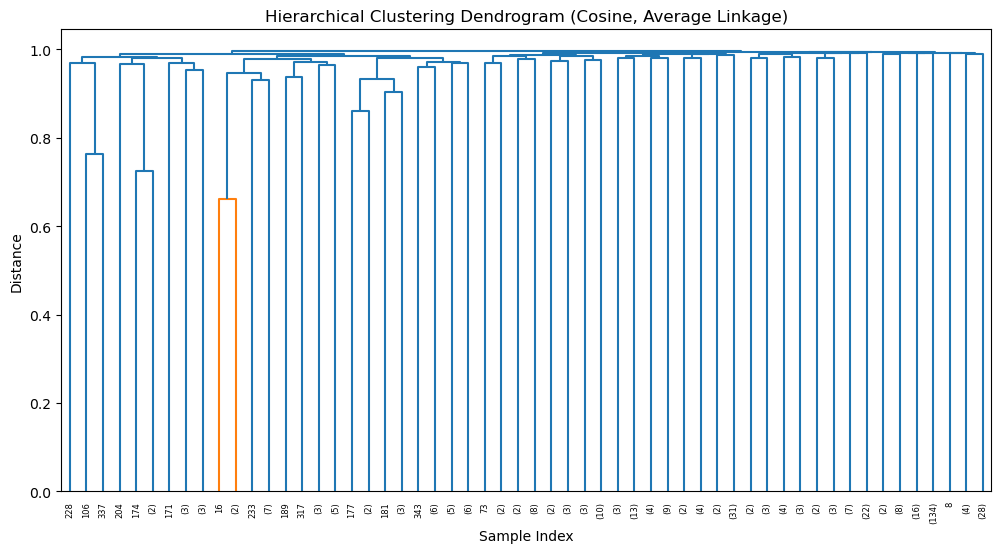

In [17]:
# plot tree plot （ compute linkage matrix
# note ：ward distance only distance ， cosine linkage method 'average'
Z = linkage(X_dense, method='average', metric='cosine')
plt.figure(figsize=(12, 6))
dendrogram(Z, truncate_mode='level', p=5)  # display 5
plt.title('Hierarchical Clustering Dendrogram (Cosine, Average Linkage)')
plt.xlabel('Sample Index')
plt.ylabel('Distance')
plt.show()

In [18]:
print("\n" + "="*60)
print(f"凝聚式层次聚类 结果（共 {n_clusters} 类）")
print("="*60)

for c in range(n_clusters):
    mask = (df['cluster_agg'] == c).values
    n_papers = mask.sum()
    if n_papers == 0:
        continue
    
    # compute text average vector
    avg_text_vec = tfidf_matrix[mask].mean(axis=0).A1
    top_indices = avg_text_vec.argsort()[-15:][::-1]
    top_words = [text_feature_names[i] for i in top_indices if avg_text_vec[i] > 0]
    
    # author statistics
    cluster_authors = df.loc[mask, 'authors_list'].explode().value_counts().head(5)
    
    print(f"\n【簇 {c+1}】 论文数量：{n_papers}")
    print(f"  代表性关键词：{', '.join(top_words[:10])}")
    print(f"  主要作者：{', '.join([f'{a}({cnt})' for a,cnt in cluster_authors.items()])}")
    print("  论文示例（最多5篇）：")
    for idx, row in df.loc[mask].head(5).iterrows():
        print(f"    - {row['title'][:80]}")
    print("-" * 60)


凝聚式层次聚类 结果（共 10 类）

【簇 1】 论文数量：134
  代表性关键词：learning, data, nmla, classification, supervised, feature, image, multi, method, model
  主要作者：Zhi-Hua Zhou(5), Prasad Tadepalli(4), Chris Ding(4), Alan Fern(4), Chen Chen(3)
  论文示例（最多5篇）：
    - Kernelized Bayesian Transfer Learning
    - "Source Free" Transfer Learning for Text Classification
    - Hybrid Singular Value Thresholding for Tensor Completion
    - Locality Preserving Hashing
    - Online Classification Using a Voted RDA Method
------------------------------------------------------------

【簇 2】 论文数量：34
  代表性关键词：language, natural language, natural, visual, translation, word, recognition, models, knowledge, student
  主要作者：Zheng Chen(2), Sumit Gulwani(2), Jian-Yun Nie(2), Alessandro Sordoni(2), Ming Zhou(2)
  论文示例（最多5篇）：
    - Towards Understanding Unscripted Gesture and Language Input for Human-Robot Inte
    - Sketch Recognition with Natural Correction and Editing
    - Predicting Emotions in User-Generated Videos
    - Emotion Cl

In [19]:
scores['Agglomerative'] = silhouette_score(X_dense, df['cluster_agg'], metric='cosine')
print(f"\n轮廓系数（-1到1，越高越好）：{scores['Agglomerative']:.3f}")


轮廓系数（-1到1，越高越好）：0.011


### Experiment notes — 27

Study clustering methods and visualize their assignments.

*English presentation summary; the complete original narrative is preserved in `archive/original_notebook.ipynb`.*

### Experiment notes — 28

Study clustering methods and visualize their assignments. Key techniques: KMeans.

*English presentation summary; the complete original narrative is preserved in `archive/original_notebook.ipynb`.*

In [20]:
# two KMeans（ split hierarchical clustering one
bisect = BisectingKMeans(n_clusters=n_clusters, random_state=RANDOM_SEED, bisecting_strategy='largest_cluster')
df['cluster_bisect'] = bisect.fit_predict(combined_matrix_norm)

In [21]:
print("\n" + "="*60)
print(f"分裂式层次聚类 结果（共 {n_clusters} 类）")
print("="*60)

for c in range(n_clusters):
    mask = (df['cluster_bisect'] == c).values
    n_papers = mask.sum()
    if n_papers == 0:
        continue
    
    # compute text average vector
    avg_text_vec = tfidf_matrix[mask].mean(axis=0).A1
    top_indices = avg_text_vec.argsort()[-15:][::-1]
    top_words = [text_feature_names[i] for i in top_indices if avg_text_vec[i] > 0]
    
    # author statistics
    cluster_authors = df.loc[mask, 'authors_list'].explode().value_counts().head(5)
    
    print(f"\n【簇 {c+1}】 论文数量：{n_papers}")
    print(f"  代表性关键词：{', '.join(top_words[:10])}")
    print(f"  主要作者：{', '.join([f'{a}({cnt})' for a,cnt in cluster_authors.items()])}")
    print("  论文示例（最多5篇）：")
    for idx, row in df.loc[mask].head(5).iterrows():
        print(f"    - {row['title'][:80]}")
    print("-" * 60)


分裂式层次聚类 结果（共 10 类）

【簇 1】 论文数量：65
  代表性关键词：social, planning, game, model, reasoning, krr, based, choice, gtep, language
  主要作者：Haris Aziz(2), Guy Van den Broeck(2), Ariel Procaccia(2), Ioannis Caragiannis(2), Vincent Conitzer(2)
  论文示例（最多5篇）：
    - A Generalization of Probabilistic Serial to Randomized Social Choice
    - Lifetime Lexical Variation in Social Media
    - The Importance of Cognition and Affect for Artificially Intelligent Decision Mak
    - The Complexity of Reasoning with FODD and GFODD
    - Predicting Emotions in User-Generated Videos
------------------------------------------------------------

【簇 2】 论文数量：52
  代表性关键词：search, planning, problems, algorithm, distributed, solving, problem, hso, constraints, time
  主要作者：William Yeoh(3), Sven Koenig(2), Neil Burch(2), Nguyen Duc Thien(2), Michael Bowling(2)
  论文示例（最多5篇）：
    - Fraudulent Support Telephone Number Identification Based on Co-occurrence Inform
    - Solving Uncertain MDPs by Reusing State Information and Plan

In [22]:
scores['BisectingKMeans'] = silhouette_score(combined_matrix_norm, df['cluster_bisect'], metric='cosine')
print(f"\n轮廓系数（-1到1，越高越好）：{scores['BisectingKMeans']:.3f}")


轮廓系数（-1到1，越高越好）：-0.001


### Experiment notes — 32

Study clustering methods and visualize their assignments.

*English presentation summary; the complete original narrative is preserved in `archive/original_notebook.ipynb`.*

In [23]:
# K-medoids (PAM)
# based on PAM (Partitioning Around Medoids) ， define distance （ distance
from scipy.spatial.distance import cdist
from sklearn.base import BaseEstimator, ClusterMixin
from sklearn.utils import check_random_state

class KMedoidsPAM(BaseEstimator, ClusterMixin):
    """
    K-medoids clustering using PAM algorithm.
    Supports arbitrary distance metrics via scipy.spatial.distance.cdist.
    """
    def __init__(self, n_clusters=8, metric='cosine', max_iter=100, random_state=None):
        self.n_clusters = n_clusters
        self.metric = metric
        self.max_iter = max_iter
        self.random_state = random_state
        
    def fit(self, X, y=None):
        X = np.asarray(X)
        n_samples = X.shape[0]
        random_state = check_random_state(self.random_state)
        
        # 1. BUILD: initialize medoids
        initial_medoid_indices = random_state.choice(n_samples, self.n_clusters, replace=False)
        medoid_indices = initial_medoid_indices.copy()
        
        # compute distance matrix
        D = cdist(X, X, metric=self.metric)
        
        # label
        labels = np.argmin(D[medoid_indices], axis=0)
        # compute （ sample to medoid distance and
        best_cost = np.sum(D[medoid_indices[labels], np.arange(n_samples)])
        
        # 2. SWAP
        for iteration in range(self.max_iter):
            changed = False
            # each medoid attempt
            for i in range(self.n_clusters):
                current_medoid = medoid_indices[i]
                # all medoid sample
                candidate_mask = np.ones(n_samples, dtype=bool)
                candidate_mask[medoid_indices] = False
                candidates = np.where(candidate_mask)[0]
                
                best_candidate = None
                best_swap_cost = best_cost
                
                for candidate in candidates:
                    temp_medoids = medoid_indices.copy()
                    temp_medoids[i] = candidate
                    temp_labels = np.argmin(D[temp_medoids], axis=0)
                    temp_cost = np.sum(D[temp_medoids[temp_labels], np.arange(n_samples)])
                    
                    if temp_cost < best_swap_cost:
                        best_swap_cost = temp_cost
                        best_candidate = candidate
                        temp_best_labels = temp_labels
                
                if best_candidate is not None:
                    medoid_indices[i] = best_candidate
                    best_cost = best_swap_cost
                    labels = temp_best_labels
                    changed = True
                    # to one ， break loop ， again loop
                    # PAM ： one medoid ， again all medoid
                    break
            if not changed:
                break
                
        self.medoid_indices_ = medoid_indices
        self.labels_ = labels
        self.inertia_ = best_cost
        return self
    
    def fit_predict(self, X, y=None):
        self.fit(X)
        return self.labels_

In [24]:
# X_dense define for
kmedoids = KMedoidsPAM(n_clusters=10, metric='cosine', random_state=42)
df['cluster_kmedoids'] = kmedoids.fit_predict(X_dense)

# inspect medoids
print("Medoid papers:")
for idx in kmedoids.medoid_indices_:
    print(f"  - {df.iloc[idx]['title'][:60]}")

Medoid papers:
  - A Game-theoretic Analysis of Catalog Optimization
  - The Computational Rise and Fall of Fairness
  - Non-convex feature learning via $\ell_{p,\infty}$ operator
  - Coactive Learning for Locally Optimal Problem Solving
  - Computing Contingent Plans via Fully Observable Non-Determin
  - Labeling Complicated Objects: Multi-View Multi-Instance Mult
  - Dynamic Bayesian Probabilistic Matrix Factorization
  - Cross-Domain Metric Learning Based on Information Theory
  - Video Recovery via Low-Rank Tensor Completion with Spatio-Te
  - Fast consistency checking of very large real-world RCC-8 con


In [25]:
print("\n" + "="*60)
print(f"K-Mediods 聚类结果（共 {n_clusters} 类）")
print("="*60)

# take all medoid table （ 0 to n_clusters-1
medoid_indices = kmedoids.medoid_indices_

for c in range(n_clusters):
    mask = (df['cluster_kmedoids'] == c).values
    n_papers = mask.sum()
    if n_papers == 0:
        continue

    # take medoid paper （ use table
    medoid_idx = medoid_indices[c]
    medoid_title = df.iloc[medoid_idx]['title']
    
    # compute text average vector
    avg_text_vec = tfidf_matrix[mask].mean(axis=0).A1
    top_indices = avg_text_vec.argsort()[-15:][::-1]
    top_words = [text_feature_names[i] for i in top_indices if avg_text_vec[i] > 0]
    
    # author statistics
    cluster_authors = df.loc[mask, 'authors_list'].explode().value_counts().head(5)
    
    print(f"\n【簇 {c+1}】 论文数量：{n_papers}")
    print(f"  Medoid 标题：{medoid_title}")
    print(f"  代表性关键词：{', '.join(top_words[:10])}")
    print(f"  主要作者：{', '.join([f'{a}({cnt})' for a,cnt in cluster_authors.items()])}")
    print("  论文示例（最多5篇）：")
    for idx, row in df.loc[mask].head(5).iterrows():
        print(f"    - {row['title'][:80]}")
    print("-" * 60)


K-Mediods 聚类结果（共 10 类）

【簇 1】 论文数量：52
  Medoid 标题：A Game-theoretic Analysis of Catalog Optimization
  代表性关键词：game, gtep, social, choice, social choice, equilibrium, mechanism, games, voting, theory
  主要作者：Vincent Conitzer(4), Craig Boutilier(4), Haris Aziz(3), Joel Oren(3), Martin Lackner(3)
  论文示例（最多5篇）：
    - A Generalization of Probabilistic Serial to Randomized Social Choice
    - Game-theoretic Resource Allocation for Protecting Large Public Events
    - A Parameterized Complexity Analysis of Generalized CP-Nets
    - Solving Imperfect Information Games Using Decomposition
    - Online (Budgeted) Social Choice
------------------------------------------------------------

【簇 2】 论文数量：13
  Medoid 标题：The Computational Rise and Fall of Fairness
  代表性关键词：games, goods, envy, allocations, gtep, exchange, envy free, voting, agents, game
  主要作者：Ariel Procaccia(7), Tuomas Sandholm(4), John Dickerson(2), Jeremy Karp(2), David Kurokawa(2)
  论文示例（最多5篇）：
    - Multi-Organ Exchange: The Whole is

In [26]:
scores['KMedoids'] = silhouette_score(X_dense, df['cluster_kmedoids'], metric='cosine')
print(f"\n轮廓系数（-1到1，越高越好）：{scores['KMedoids']:.3f}")


轮廓系数（-1到1，越高越好）：0.008


### Experiment notes — 37

Review the implementation and results for this stage of the experiment.

*English presentation summary; the complete original narrative is preserved in `archive/original_notebook.ipynb`.*

KMeans              : 0.005
Agglomerative       : 0.011
BisectingKMeans     : -0.001
KMedoids            : 0.008


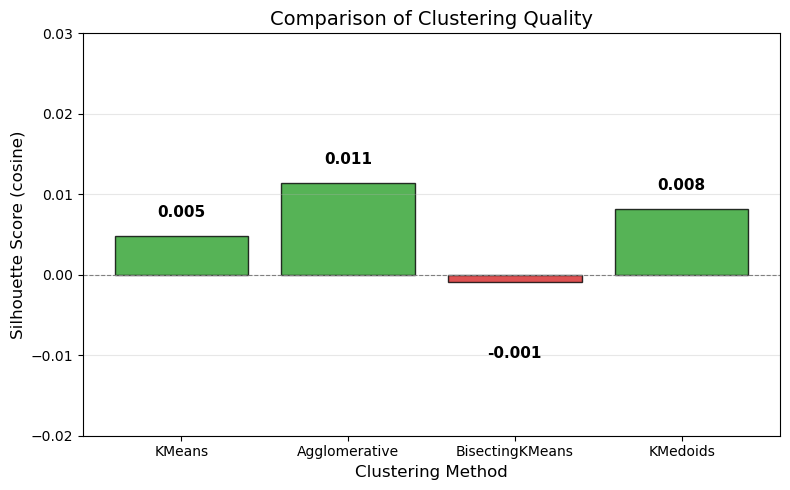

In [27]:
for name, score in scores.items():
    print(f"{name:20s}: {score:.3f}")

# visualization
names = list(scores.keys())
values = list(scores.values())

# value ， value
colors = ['#2ca02c' if v >= 0 else '#d62728' for v in values]

plt.figure(figsize=(8, 5))
bars = plt.bar(names, values, color=colors, alpha=0.8, edgecolor='black')

# value
for bar, val in zip(bars, values):
    plt.text(bar.get_x() + bar.get_width()/2, 
             bar.get_height() + (0.002 if val >= 0 else -0.008),
             f'{val:.3f}', ha='center', va='bottom' if val >= 0 else 'top',
             fontsize=11, fontweight='bold')

plt.axhline(y=0, color='gray', linestyle='--', linewidth=0.8)
plt.xlabel('Clustering Method', fontsize=12)
plt.ylabel('Silhouette Score (cosine)', fontsize=12)
plt.title('Comparison of Clustering Quality', fontsize=14)
plt.ylim(min(-0.02, min(values)-0.01), max(0.03, max(values)+0.01))
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

### Experiment notes — 39

Interpretation of results and model behavior. Study clustering methods and visualize their assignments.

*English presentation summary; the complete original narrative is preserved in `archive/original_notebook.ipynb`.*

### Experiment notes — 40

Review the implementation and results for this stage of the experiment.

*English presentation summary; the complete original narrative is preserved in `archive/original_notebook.ipynb`.*

In [28]:
X = X_dense

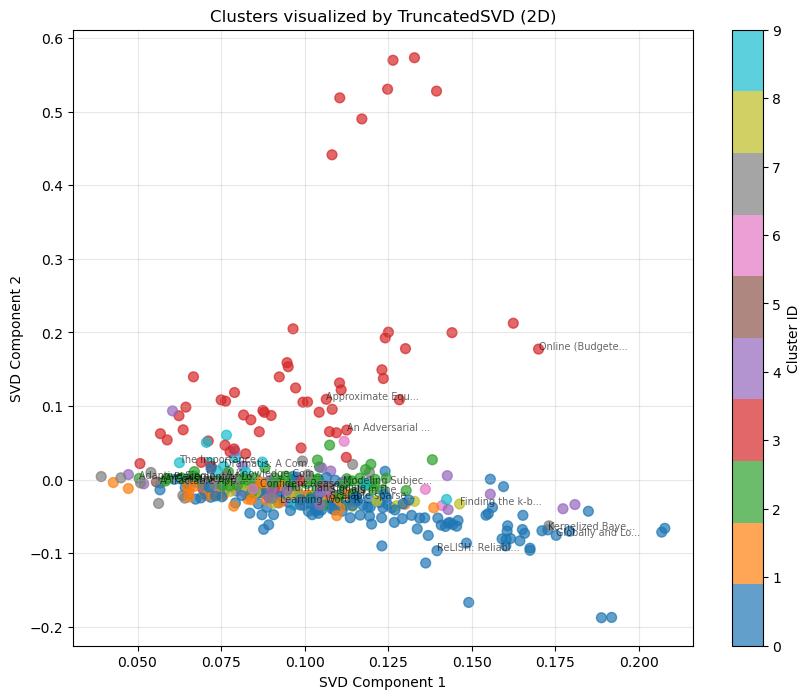

In [29]:
# TruncatedSVD（， sparse high data
# dimensionality reduction to 2
svd = TruncatedSVD(n_components=2, random_state=RANDOM_SEED)
X_2d_svd = svd.fit_transform(X)

# create
plt.figure(figsize=(10, 8))
scatter = plt.scatter(X_2d_svd[:, 0], X_2d_svd[:, 1], 
                      c=df['cluster_agg'], cmap='tab10', alpha=0.7, s=50)
plt.colorbar(scatter, label='Cluster ID')
plt.title('Clusters visualized by TruncatedSVD (2D)')
plt.xlabel('SVD Component 1')
plt.ylabel('SVD Component 2')
plt.grid(alpha=0.3)

# label
for i in range(len(X_2d_svd)):
    if i % 20 == 0:  # 20 one
        plt.annotate(df.iloc[i]['title'][:15]+'...', 
                     (X_2d_svd[i, 0], X_2d_svd[i, 1]), fontsize=7, alpha=0.6)
plt.show()

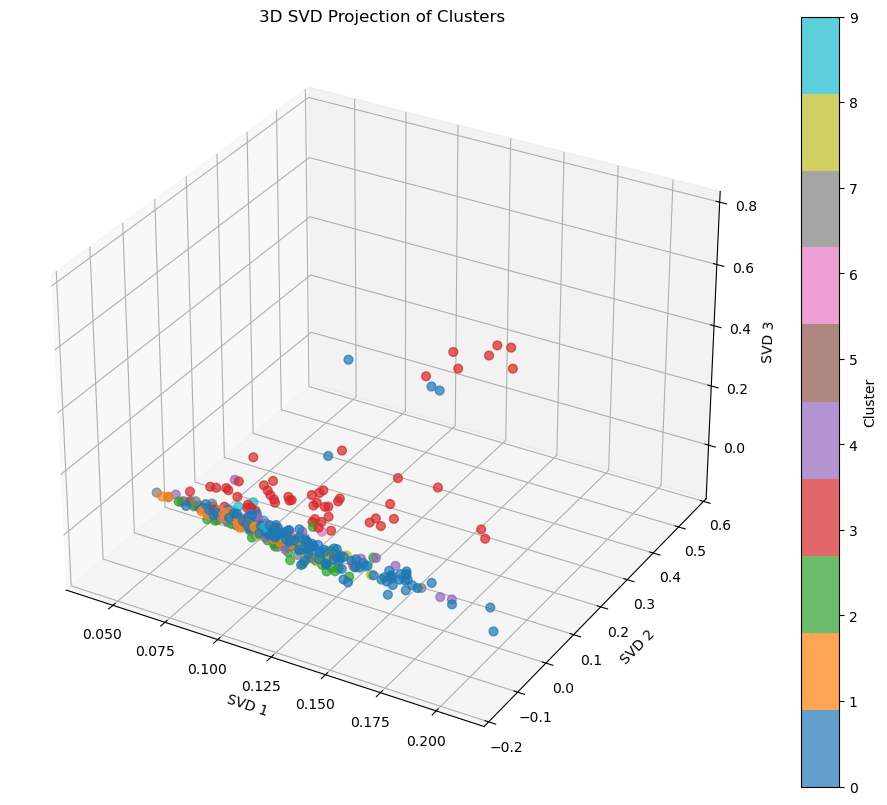

In [30]:
from mpl_toolkits.mplot3d import Axes3D

svd_3d = TruncatedSVD(n_components=3, random_state=RANDOM_SEED)
X_3d = svd_3d.fit_transform(X)

fig = plt.figure(figsize=(12, 10))
ax = fig.add_subplot(111, projection='3d')
sc = ax.scatter(X_3d[:, 0], X_3d[:, 1], X_3d[:, 2], 
                c=df['cluster_agg'], cmap='tab10', s=40, alpha=0.7)
plt.colorbar(sc, ax=ax, label='Cluster')
ax.set_title('3D SVD Projection of Clusters')
ax.set_xlabel('SVD 1')
ax.set_ylabel('SVD 2')
ax.set_zlabel('SVD 3')
plt.show()

### Experiment notes — 44

Interpret the reported empirical results.

*English presentation summary; the complete original narrative is preserved in `archive/original_notebook.ipynb`.*

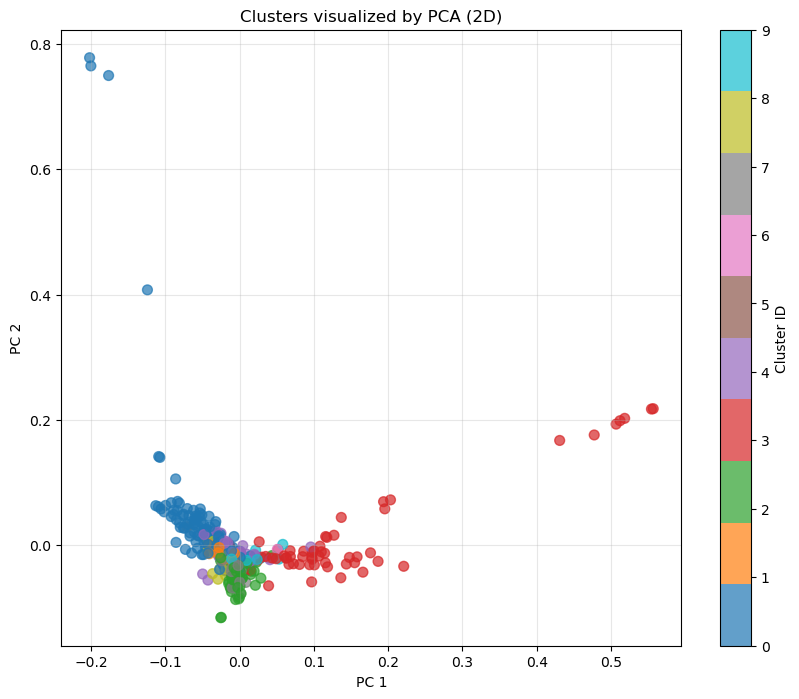

In [31]:
# PCA（ data or low data
pca = PCA(n_components=2, random_state=RANDOM_SEED)
X_2d_pca = pca.fit_transform(X)

plt.figure(figsize=(10, 8))
scatter = plt.scatter(X_2d_pca[:, 0], X_2d_pca[:, 1], 
                      c=df['cluster_agg'], cmap='tab10', alpha=0.7, s=50)
plt.colorbar(scatter, label='Cluster ID')
plt.title('Clusters visualized by PCA (2D)')
plt.xlabel('PC 1')
plt.ylabel('PC 2')
plt.grid(alpha=0.3)
plt.show()

### Experiment notes — 46

Interpret the reported empirical results.

*English presentation summary; the complete original narrative is preserved in `archive/original_notebook.ipynb`.*

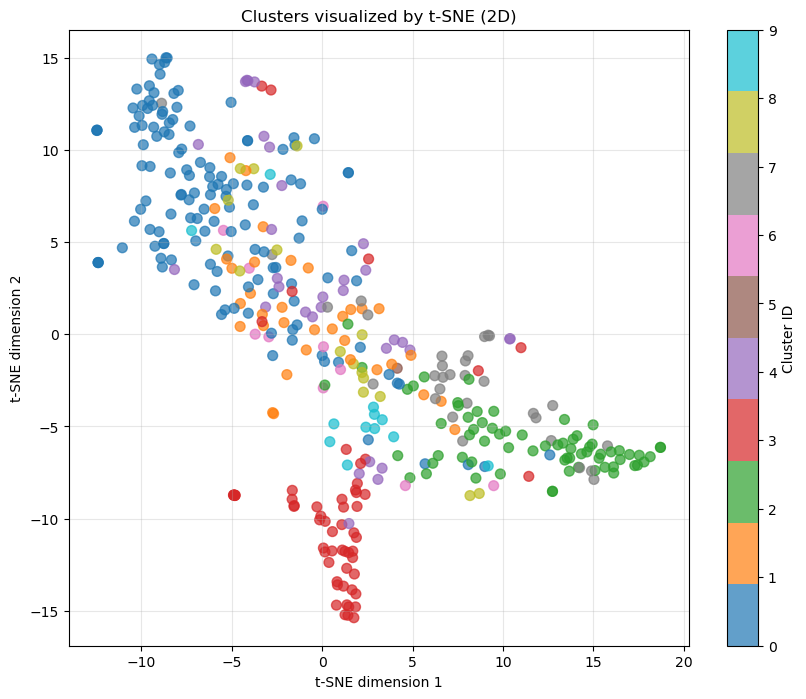

In [32]:
# t-SNE（ retain ， compute
# t-SNE input ， high data PCA dimensionality reduction 5
# step 1： TruncatedSVD dimensionality reduction
pre_svd = TruncatedSVD(n_components=5, random_state=RANDOM_SEED)
X_pre = pre_svd.fit_transform(X)

tsne = TSNE(
    n_components=2,
    random_state=RANDOM_SEED,
    perplexity=50,
    learning_rate='auto',    # Implementation note
    init='pca'               # use PCA initialize
)
X_2d_tsne = tsne.fit_transform(X_pre)

# plot
plt.figure(figsize=(10, 8))
scatter = plt.scatter(
    X_2d_tsne[:, 0], X_2d_tsne[:, 1],
    c=df['cluster_agg'], cmap='tab10', alpha=0.7, s=50
)
plt.colorbar(scatter, label='Cluster ID')
plt.title('Clusters visualized by t-SNE (2D)')
plt.xlabel('t-SNE dimension 1')
plt.ylabel('t-SNE dimension 2')
plt.grid(alpha=0.3)
plt.show()

### Experiment notes — 48

Interpret the reported empirical results.

*English presentation summary; the complete original narrative is preserved in `archive/original_notebook.ipynb`.*